1(b) Split data to train and test

In [55]:
from pathlib import Path
import pandas as pd

data_path = Path("../data/AReM")

columns = [
    "time", "avg_rss12", "var_rss12",
    "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"
]

train_data, test_data = [], []
train_labels, test_labels = [], []

for folder in sorted(data_path.iterdir()):
    if not folder.is_dir():
        continue

    activity = folder.name

    for file in sorted(folder.glob("dataset*.csv")):
        number = int(file.stem.replace("dataset", ""))

        data = pd.read_csv(
            file,
            comment="#",
            header=None,
            sep=r"[,\s]+",
            engine="python",
            usecols=range(7),
            names=columns
        )

        # First 2 files for bending; first 3 files for other activities
        test_limit = 2 if activity in ["bending1", "bending2"] else 3

        if number <= test_limit:
            test_data.append(data)
            test_labels.append(activity)
        else:
            train_data.append(data)
            train_labels.append(activity)

print("Training samples:", len(train_data))
print("Test samples:", len(test_data))

Training samples: 69
Test samples: 19


1(c)i time-domain features are usually used:

Minimum and maximum: the lowest and highest values.

Mean and median: measures of the central value.

Standard deviation and variance: measures of how spread out the values are.

First and third quartiles: the 25th and 75th percentiles.

Range and interquartile range: maximum minus minimum, and third quartile minus first quartile.

Skewness and kurtosis: measures of the shape of the value distribution.

Root mean square (RMS) and energy: measures of signal magnitude.

Autocorrelation: the relationship between a time series and its lagged values.

Mean absolute change: the average absolute difference between consecutive values.

Number of peaks and zero crossings: measures of fluctuations in the signal.

1(c)ii

In [56]:
all_data = train_data + test_data

rows = []

for data in all_data:
    features = {}

    for i, column in enumerate(data.columns[1:], start=1):
        series = data[column]

        features[f"min{i}"] = series.min()
        features[f"max{i}"] = series.max()
        features[f"mean{i}"] = series.mean()
        features[f"median{i}"] = series.median()
        features[f"std{i}"] = series.std()
        features[f"1st_quart{i}"] = series.quantile(0.25)
        features[f"3rd_quart{i}"] = series.quantile(0.75)

    rows.append(features)

features_df = pd.DataFrame(rows)
features_df.index = range(1, len(features_df) + 1)
features_df.index.name = "Instance"

display(features_df)
print(features_df.shape)

,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
Instance,,,,,,,,,,,,,,,,,,,,,
1,35.00,47.40,43.954500,44.330,1.558835,43.00,45.0000,0.0,1.70,0.426250,...,1.999604,35.3625,36.500,0.0,1.79,0.493292,0.430,0.513506,0.000,0.940
2,33.00,47.75,42.179812,43.500,3.670666,39.15,45.0000,0.0,3.00,0.696042,...,3.849448,30.4575,36.330,0.0,2.18,0.613521,0.500,0.524317,0.000,1.000
3,33.00,45.75,41.678063,41.750,2.243490,41.33,42.7500,0.0,2.83,0.535979,...,2.411026,28.4575,31.250,0.0,1.79,0.383292,0.430,0.389164,0.000,0.500
4,37.00,48.00,43.454958,43.250,1.386098,42.50,45.0000,0.0,1.58,0.378083,...,2.488862,22.2500,24.000,0.0,5.26,0.679646,0.500,0.622534,0.430,0.870
5,36.25,48.00,43.969125,44.500,1.618364,43.31,44.6700,0.0,1.50,0.413125,...,3.318301,20.5000,23.750,0.0,2.96,0.555312,0.490,0.487826,0.000,0.830
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,35.50,46.25,43.174938,43.670,1.989052,42.50,44.5000,0.0,2.12,0.506583,...,2.983976,12.7500,16.500,0.0,5.72,0.911979,0.830,0.666161,0.470,1.220
85,32.75,47.00,42.760562,44.500,3.398919,41.33,45.3725,0.0,3.34,0.486167,...,4.296574,13.0000,18.565,0.0,5.73,0.842271,0.710,0.722165,0.430,1.090
86,19.33,43.50,34.227771,35.500,4.889576,30.50,37.7500,0.0,14.50,3.995729,...,3.092094,14.7500,18.670,0.0,9.74,3.394125,3.100,1.792090,2.105,4.425


(88, 42)


1(c)iii Standard Deviation and bootsrap confidence interval

In [57]:
import numpy as np

rng = np.random.default_rng(42)

# Standard deviation of each feature
feature_std = features_df.std()

# Bootstrap: sample 88 instances with replacement each time
bootstrap_std = []

for _ in range(10000):
    indices = rng.choice(len(features_df), size=len(features_df), replace=True)
    sample = features_df.iloc[indices]
    bootstrap_std.append(sample.std().to_numpy())

# 90% percentile confidence intervals
lower, upper = np.percentile(bootstrap_std, [5, 95], axis=0)

std_results = pd.DataFrame({
    "Standard Deviation": feature_std,
    "90% CI Lower": lower,
    "90% CI Upper": upper
})

display(std_results)

,Standard Deviation,90% CI Lower,90% CI Upper
min1,9.569975,8.244286,10.758793
max1,4.394362,3.327264,5.306152
mean1,5.335718,4.705556,5.878507
median1,5.440054,4.795744,5.993590
std1,1.772153,1.573015,1.949089
1st_quart1,6.153590,5.569467,6.639432
3rd_quart1,5.138925,4.327216,5.826745
min2,0.000000,0.000000,0.000000
max2,5.062729,4.617742,5.410284
mean2,1.574164,1.394410,1.706190


1(c)iv I select mean, standard deviation, and maximum. The mean represents the overall signal level, the standard deviation measures variability, and the maximum captures peak values. Together, they may help distinguish different activities.

2(a)i

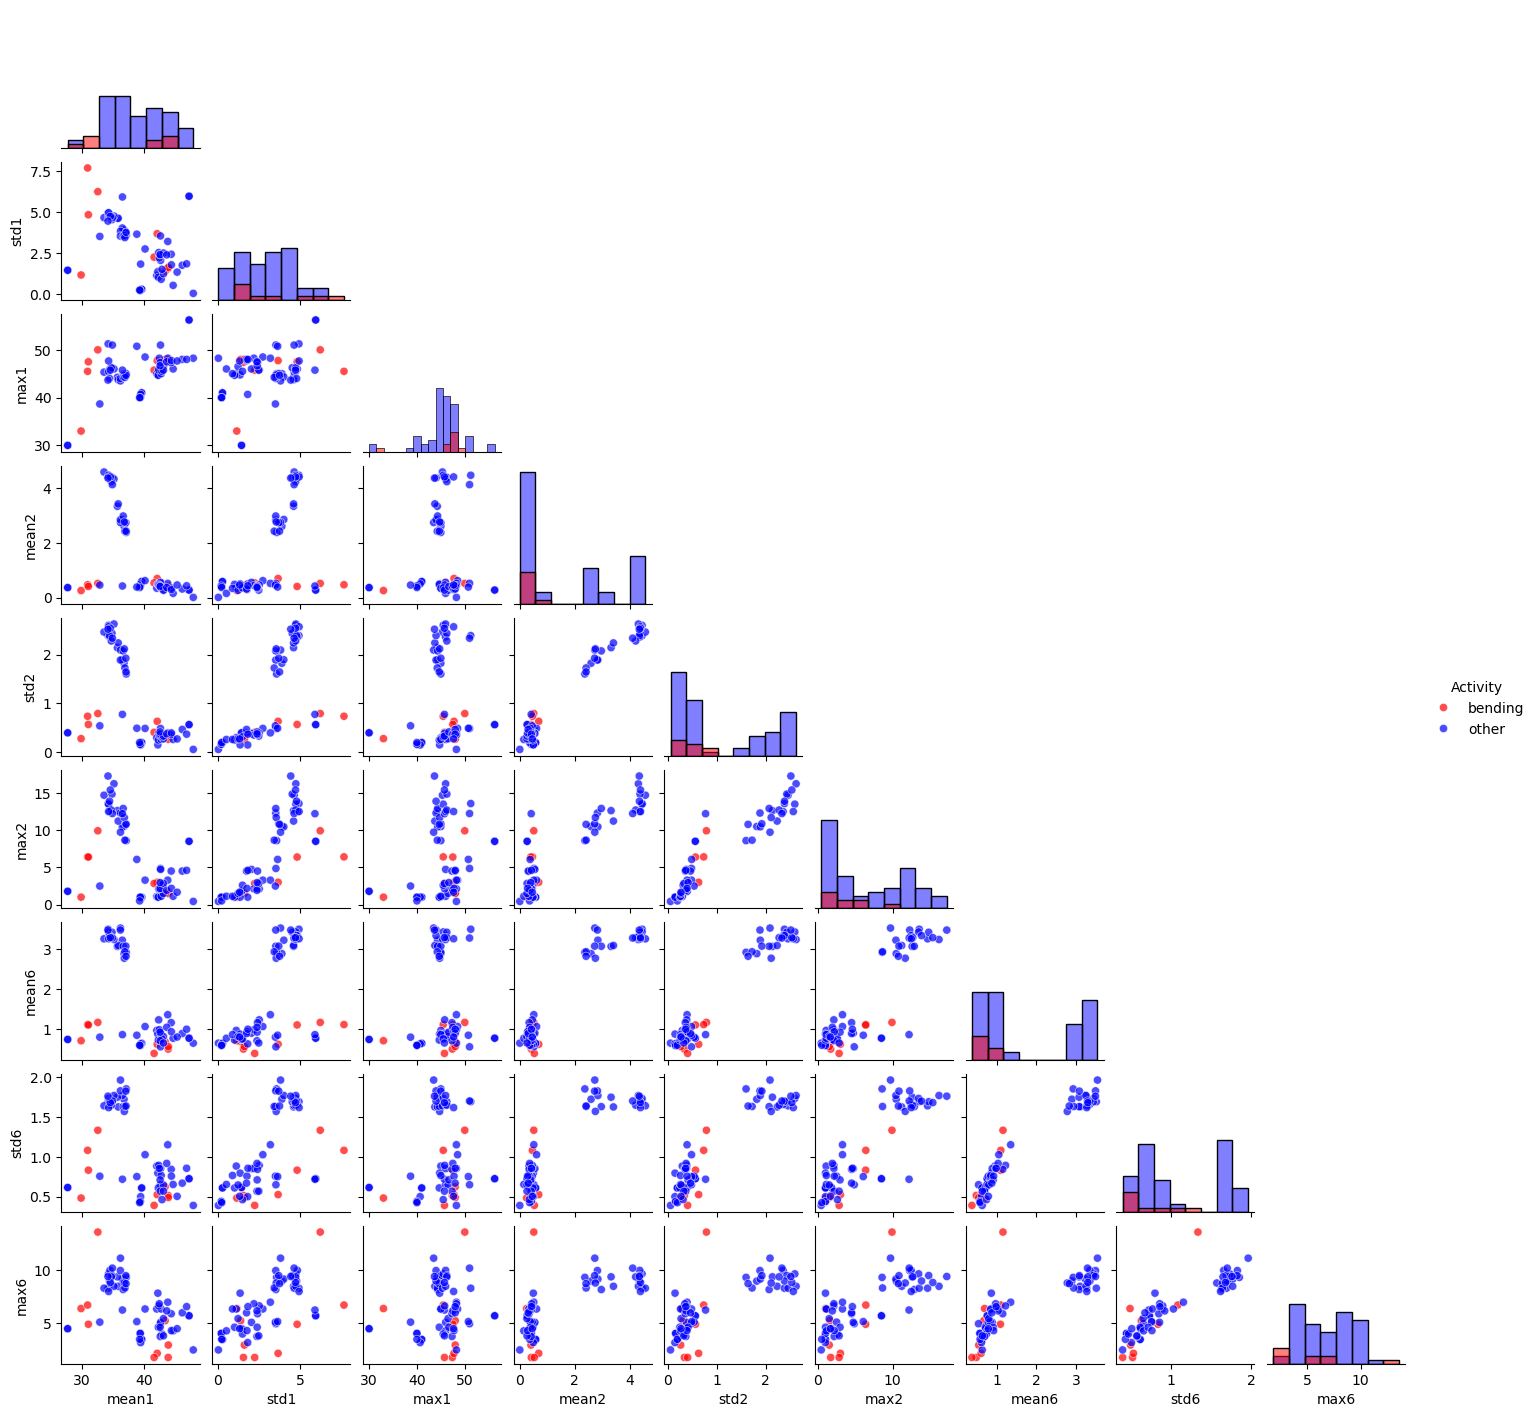

In [58]:
import seaborn as sns
import matplotlib.pyplot as plt

rows = []

for data in train_data:
    features = {}

    for i in [1, 2, 6]:
        series = data.iloc[:, i]  # Column 0 is time

        features[f"mean{i}"] = series.mean()
        features[f"std{i}"] = series.std()
        features[f"max{i}"] = series.max()

    rows.append(features)

plot_df = pd.DataFrame(rows)

plot_df["Activity"] = [
    "bending" if label in ["bending1", "bending2"] else "other"
    for label in train_labels
]

sns.pairplot(
    plot_df,
    hue="Activity",
    hue_order=["bending", "other"],
    palette={"bending": "red", "other": "blue"},
    diag_kind="hist",
    corner=True,
    height=1.6,
    plot_kws={"alpha": 0.7, "s": 35}
)

plt.show()

2(a)ii

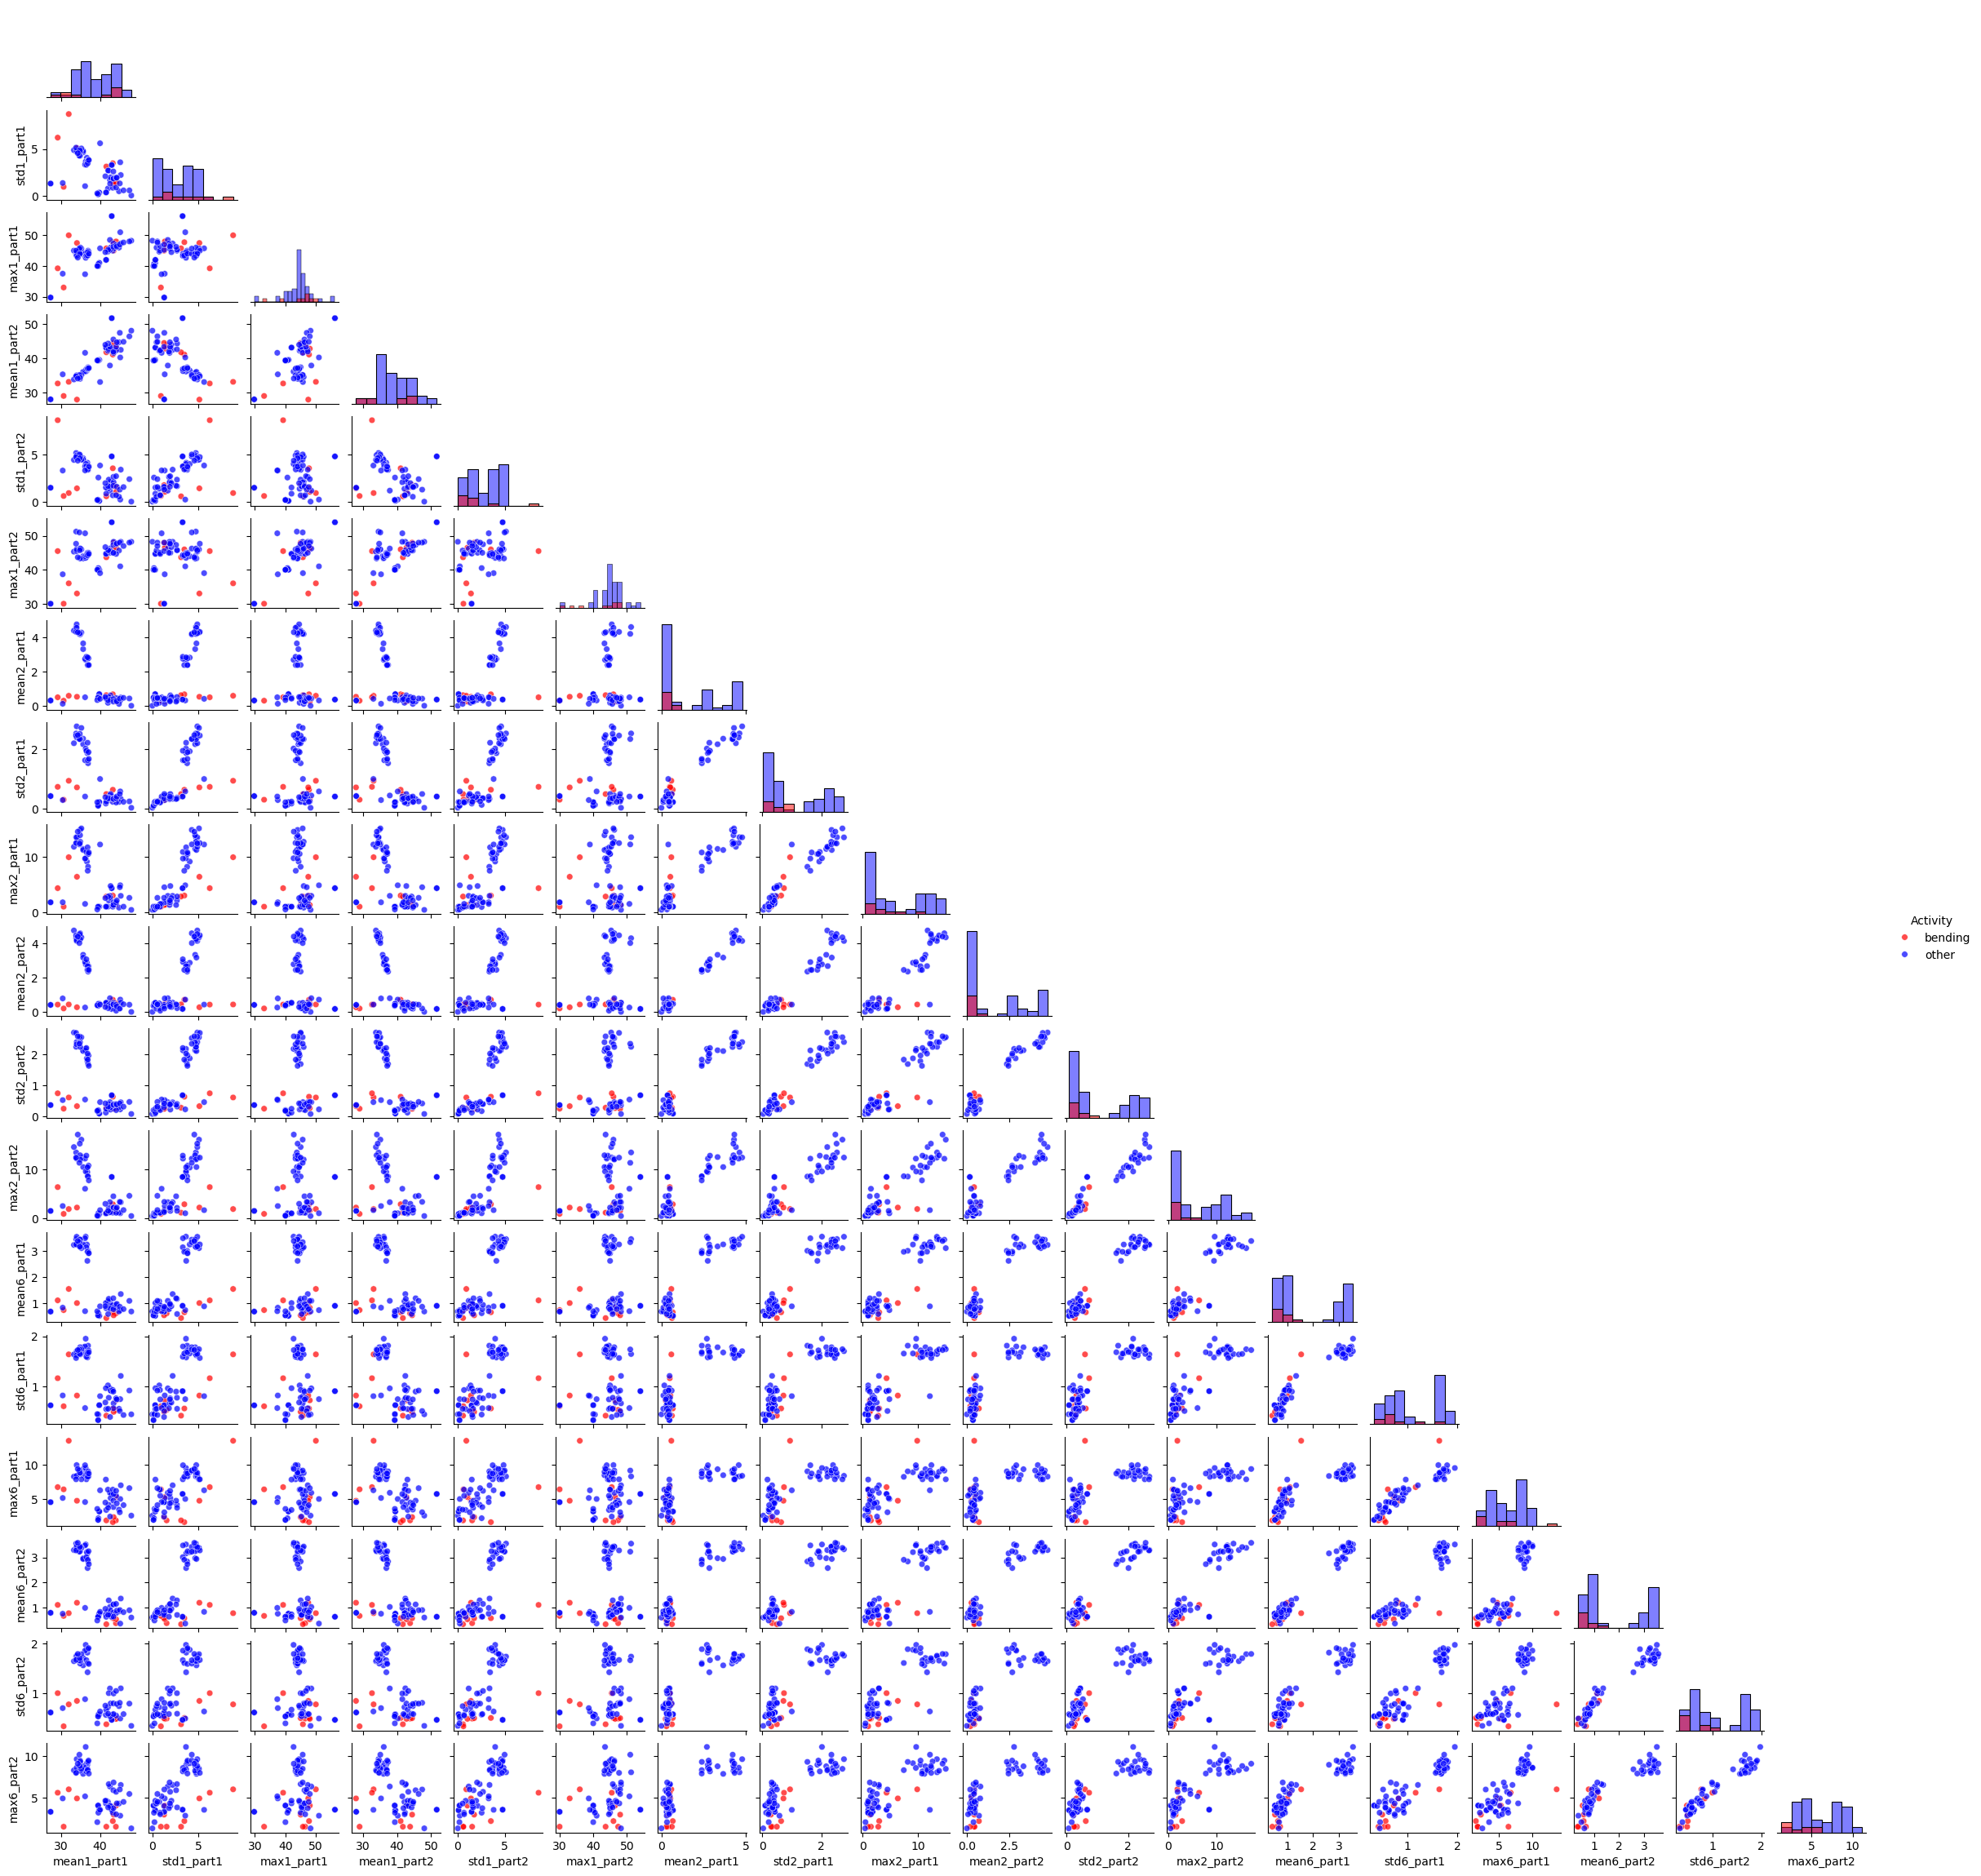

In [59]:
rows = []

for data in train_data:
    features = {}

    for i in [1, 2, 6]:
        parts = np.array_split(data.iloc[:, i].to_numpy(), 2)

        for j, part in enumerate(parts, start=1):
            features[f"mean{i}_part{j}"] = part.mean()
            features[f"std{i}_part{j}"] = part.std(ddof=1)
            features[f"max{i}_part{j}"] = part.max()

    rows.append(features)

plot_df_split = pd.DataFrame(rows)

plot_df_split["Activity"] = [
    "bending" if label in ["bending1", "bending2"] else "other"
    for label in train_labels
]

sns.pairplot(
    plot_df_split,
    hue="Activity",
    hue_order=["bending", "other"],
    palette={"bending": "red", "other": "blue"},
    diag_kind="hist",
    corner=True,
    height=1.3,
    plot_kws={"alpha": 0.7, "s": 30}
)

plt.show()

After splitting each time series into two halves, the overall patterns remain similar. Some feature pairs show clearer separation between bending and other activities, but substantial overlap remains in many plots. 

2(a)iii I use RFE with 5-fold stratified cross-validation to select the best combination of l and p.

In [60]:
def extract_features(data_list, l):
    rows = []

    for data in data_list:
        features = {}

        for i in range(1, 7):
            parts = np.array_split(data.iloc[:, i].to_numpy(), l)

            for j, part in enumerate(parts, start=1):
                values = {
                    "min": part.min(),
                    "max": part.max(),
                    "mean": part.mean(),
                    "median": np.median(part),
                    "std": part.std(ddof=1),
                    "q1": np.quantile(part, 0.25),
                    "q3": np.quantile(part, 0.75)
                }

                for name, value in values.items():
                    features[f"{name}{i}_part{j}"] = value

        rows.append(features)

    return pd.DataFrame(rows)

In [61]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFECV
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# bending = 1, other = 0
y_train = np.array([
    1 if label in ["bending1", "bending2"] else 0
    for label in train_labels
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []
best_score = -1

for l in range(1, 21):
    X = extract_features(train_data, l)

    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(C=1e6, solver="lbfgs", max_iter=1000)
    )

    selector = RFECV(
        estimator=model,
        step=1,
        min_features_to_select=1,
        cv=cv,
        scoring="accuracy",
        importance_getter="named_steps.logisticregression.coef_",
        n_jobs=-1
    )

    selector.fit(X, y_train)

    score = selector.cv_results_["mean_test_score"].max()
    p = selector.n_features_

    results.append({
        "l": l,
        "p": p,
        "CV Accuracy": score
    })

    if score > best_score:
        best_score = score
        best_l = l
        best_p = p
        best_selector = selector
        X_train_best = X

    print(f"l = {l}, p = {p}, CV Accuracy = {score:.4f}")

results_df = pd.DataFrame(results)
display(results_df)

print("Best l:", best_l)
print("Best p:", best_p)
print("Best CV Accuracy:", round(best_score, 4))

selected_features = X_train_best.columns[best_selector.support_]
print("Selected features:", selected_features.tolist())

l = 1, p = 16, CV Accuracy = 0.9857
l = 2, p = 6, CV Accuracy = 0.9714
l = 3, p = 6, CV Accuracy = 0.9429
l = 4, p = 9, CV Accuracy = 0.9571
l = 5, p = 1, CV Accuracy = 0.9571
l = 6, p = 5, CV Accuracy = 0.9571
l = 7, p = 8, CV Accuracy = 0.9571
l = 8, p = 2, CV Accuracy = 0.9429
l = 9, p = 10, CV Accuracy = 0.9571
l = 10, p = 8, CV Accuracy = 0.9857
l = 11, p = 2, CV Accuracy = 0.9714
l = 12, p = 2, CV Accuracy = 0.9714
l = 13, p = 13, CV Accuracy = 0.9571
l = 14, p = 12, CV Accuracy = 0.9429
l = 15, p = 28, CV Accuracy = 0.9571
l = 16, p = 12, CV Accuracy = 0.9286
l = 17, p = 1, CV Accuracy = 0.9714
l = 18, p = 6, CV Accuracy = 0.9571
l = 19, p = 7, CV Accuracy = 0.9857
l = 20, p = 4, CV Accuracy = 0.9714


,l,p,CV Accuracy
0,1,16,0.985714
1,2,6,0.971429
2,3,6,0.942857
3,4,9,0.957143
4,5,1,0.957143
5,6,5,0.957143
6,7,8,0.957143
7,8,2,0.942857
8,9,10,0.957143
9,10,8,0.985714


Best l: 1
Best p: 16
Best CV Accuracy: 0.9857
Selected features: ['min1_part1', 'max1_part1', 'mean1_part1', 'q31_part1', 'max2_part1', 'max3_part1', 'q33_part1', 'max4_part1', 'median4_part1', 'q14_part1', 'min5_part1', 'max5_part1', 'mean5_part1', 'q15_part1', 'std6_part1', 'q16_part1']


The correct approach is to perform scaling and feature selection separately within each training fold, then evaluate the model on the validation fold. The wrong approach is to select features or fit the scaler using the entire training set before cross-validation, because this leaks information from the validation folds.

Stratified cross-validation approximately preserves the class proportions in each fold. This is useful because the training set contains only 9 bending samples and 60 other samples. If just randomly choosing samples, some fold may not have bending sample.

2(a)iv I use statsmodel to get p value.

         Current function value: 0.000000
         Iterations: 35


c:\Code\Anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


,Coefficient,p-value
const,-43.598607,1.000000
min1_part1,-13.585789,1.000000
max1_part1,3.184254,1.000000
mean1_part1,9.280959,1.000000
q31_part1,-26.195523,1.000000
max2_part1,-6.547319,1.000000
max3_part1,21.391067,1.000000
q33_part1,-6.180333,1.000000
max4_part1,21.260389,1.000000
median4_part1,-6.058381,1.000000


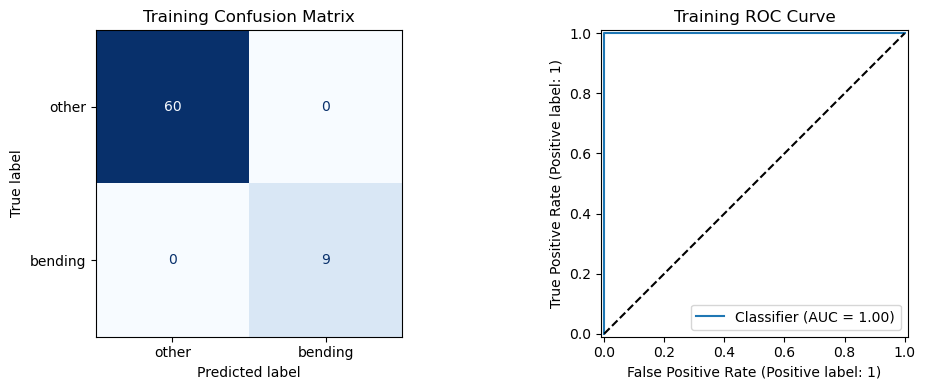

Training AUC: 1.0


In [62]:
import statsmodels.api as sm
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    roc_auc_score
)

# Select and standardize features
X_selected = best_selector.transform(X_train_best)
scaler = best_selector.estimator_.named_steps["standardscaler"]
X_scaled = scaler.transform(X_selected)

X_sm = pd.DataFrame(X_scaled, columns=selected_features)
X_sm = sm.add_constant(X_sm, has_constant="add")

# Fit logistic regression
sm_result = sm.Logit(y_train, X_sm).fit()

# Coefficients and p-values
display(pd.DataFrame({
    "Coefficient": sm_result.params,
    "p-value": sm_result.pvalues
}))

# Training predictions
y_train_prob = sm_result.predict(X_sm)
y_train_pred = (y_train_prob >= 0.5).astype(int)

# Confusion matrix and ROC curve
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay(
    confusion_matrix(y_train, y_train_pred),
    display_labels=["other", "bending"]
).plot(ax=axes[0], cmap="Blues", colorbar=False)

axes[0].set_title("Training Confusion Matrix")

RocCurveDisplay.from_predictions(
    y_train, y_train_prob, ax=axes[1]
)
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_title("Training ROC Curve")

plt.tight_layout()
plt.show()

print("Training AUC:", round(roc_auc_score(y_train, y_train_prob), 4))

2(a)v

In [63]:
from sklearn.metrics import accuracy_score

# Extract test features using the same l
X_test = extract_features(test_data, best_l)

y_test = np.array([
    1 if label in ["bending1", "bending2"] else 0
    for label in test_labels
])

# Apply the feature selection and scaler learned from training data
X_test_selected = best_selector.transform(X_test)
X_test_scaled = scaler.transform(X_test_selected)

X_test_sm = pd.DataFrame(X_test_scaled, columns=selected_features)
X_test_sm = sm.add_constant(X_test_sm, has_constant="add")
X_test_sm = X_test_sm[X_sm.columns]

# Predict using the model from part iv
y_test_prob = sm_result.predict(X_test_sm)
y_test_pred = (y_test_prob >= 0.5).astype(int)

test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Cross-validation accuracy: {best_score:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test error rate: {1 - test_accuracy:.4f}")
print(f"Correct predictions: {(y_test_pred == y_test).sum()} / {len(y_test)}")
print(f"Test - CV accuracy: {test_accuracy - best_score:+.4f}")

Cross-validation accuracy: 0.9857
Test accuracy: 1.0000
Test error rate: 0.0000
Correct predictions: 19 / 19
Test - CV accuracy: +0.0143



2(a)vi

Yes. The training confusion matrix shows that all 60 non-bending samples and all 9 bending samples are classified correctly, with an AUC of 1.00. This indicates that the selected features separate the training classes. The statsmodels model also failed to converge while its loss approached zero, which is consistent with complete separation. In this situation, the logistic regression coefficients can grow without bound, making the coefficient estimates and p-values unreliable.

2(a)vii

The classes are imbalanced: there are 60 non-bending samples and only 9 bending samples. I keep all non-bending samples and sample bending observations with replacement to obtain 60 observations in each class. I then refit logistic regression and adjust the intercept to account for the changed class proportions, using the original training proportion as an estimate of the target proportion. Because resampling does not resolve class separation, I limit the fitting iterations. The confusion matrix, ROC curve, and AUC are evaluated on the original training set.

c:\Code\Anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


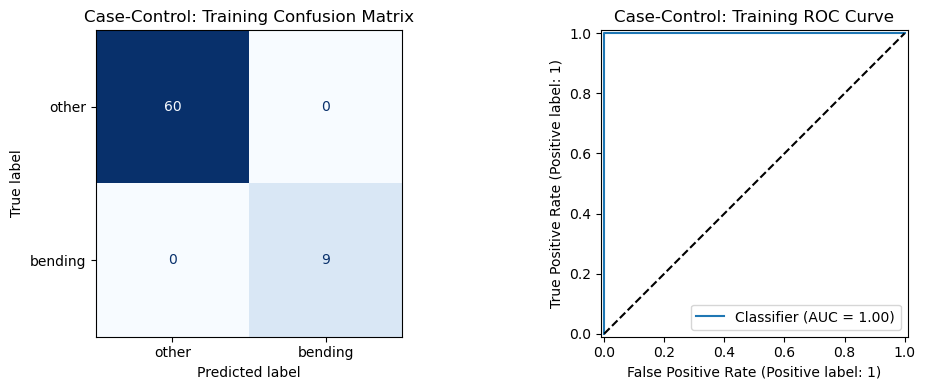

Training accuracy: 1.0
Training AUC: 1.0
Adjusted intercept: -9.072876965149042


In [64]:
from scipy.special import expit

# Case-control sampling: 60 other and 60 bending
rng = np.random.default_rng(42)

other_indices = np.where(y_train == 0)[0]
bending_indices = np.where(y_train == 1)[0]

sampled_bending = rng.choice(
    bending_indices,
    size=len(other_indices),
    replace=True
)

sample_indices = np.concatenate([other_indices, sampled_bending])

X_case = X_sm.iloc[sample_indices].reset_index(drop=True)
y_case = y_train[sample_indices]

# Limit iterations because the training classes are separable
case_result = sm.Logit(y_case, X_case).fit(
    method="lbfgs",
    maxiter=10,
    disp=False
)

# Correct the intercept for the change in class proportions
pi = y_train.mean()
pi_sample = y_case.mean()

case_params = case_result.params.copy()
case_params["const"] += (
    np.log(pi / (1 - pi))
    - np.log(pi_sample / (1 - pi_sample))
)

# Evaluate on the ORIGINAL training set
case_prob = expit(X_sm @ case_params)
case_pred = (case_prob >= 0.5).astype(int)

case_cm = confusion_matrix(y_train, case_pred)
case_auc = roc_auc_score(y_train, case_prob)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay(
    case_cm,
    display_labels=["other", "bending"]
).plot(ax=axes[0], cmap="Blues", colorbar=False)

axes[0].set_title("Case-Control: Training Confusion Matrix")

RocCurveDisplay.from_predictions(
    y_train, case_prob, ax=axes[1]
)
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_title("Case-Control: Training ROC Curve")

plt.tight_layout()
plt.show()

print("Training accuracy:", round(accuracy_score(y_train, case_pred), 4))
print("Training AUC:", round(case_auc, 4))
print("Adjusted intercept:", case_params["const"])

2(b)i

In [65]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

C_values = np.logspace(-4, 4, 9)

l1_results = []
best_l1_score = -1

for l in range(1, 21):
    X = extract_features(train_data, l)

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(
            penalty="l1",
            solver="liblinear",
            max_iter=5000,
            random_state=42
        ))
    ])

    search = GridSearchCV(
        estimator=model,
        param_grid={"logistic__C": C_values},
        scoring="accuracy",
        cv=cv,
        n_jobs=-1
    )

    search.fit(X, y_train)

    score = search.best_score_
    C = search.best_params_["logistic__C"]
    fitted_model = search.best_estimator_
    coefficients = fitted_model.named_steps["logistic"].coef_[0]
    nonzero = np.count_nonzero(coefficients)

    l1_results.append({
        "l": l,
        "C": C,
        "Nonzero Features": nonzero,
        "CV Accuracy": score
    })

    if score > best_l1_score:
        best_l1_score = score
        best_l1_l = l
        best_l1_C = C
        best_l1_model = fitted_model
        X_train_l1 = X

    print(
        f"l = {l}, C = {C:g}, "
        f"Nonzero Features = {nonzero}, CV Accuracy = {score:.4f}"
    )

l1_results_df = pd.DataFrame(l1_results)
display(l1_results_df)

# Features retained by the final model
best_l1_coef = best_l1_model.named_steps["logistic"].coef_[0]
l1_selected_features = X_train_l1.columns[best_l1_coef != 0]

print("Best l:", best_l1_l)
print("Best C:", best_l1_C)
print("Best CV Accuracy:", round(best_l1_score, 4))
print("Number of selected features:", len(l1_selected_features))
print("Selected features:", l1_selected_features.tolist())

l = 1, C = 10000, Nonzero Features = 36, CV Accuracy = 0.9857
l = 2, C = 10, Nonzero Features = 11, CV Accuracy = 0.9714
l = 3, C = 1, Nonzero Features = 8, CV Accuracy = 0.9571
l = 4, C = 10000, Nonzero Features = 125, CV Accuracy = 0.9571
l = 5, C = 100, Nonzero Features = 22, CV Accuracy = 0.9418
l = 6, C = 100, Nonzero Features = 22, CV Accuracy = 0.9571
l = 7, C = 100, Nonzero Features = 25, CV Accuracy = 0.9560
l = 8, C = 100, Nonzero Features = 29, CV Accuracy = 0.9429
l = 9, C = 10000, Nonzero Features = 141, CV Accuracy = 0.9571
l = 10, C = 100, Nonzero Features = 34, CV Accuracy = 0.9714
l = 11, C = 1, Nonzero Features = 8, CV Accuracy = 0.9571
l = 12, C = 1, Nonzero Features = 9, CV Accuracy = 0.9714
l = 13, C = 1, Nonzero Features = 11, CV Accuracy = 0.9571
l = 14, C = 10, Nonzero Features = 21, CV Accuracy = 0.9571
l = 15, C = 1000, Nonzero Features = 90, CV Accuracy = 0.9429
l = 16, C = 100, Nonzero Features = 48, CV Accuracy = 0.9429
l = 17, C = 1000, Nonzero Features = 

,l,C,Nonzero Features,CV Accuracy
0,1,10000.0,36,0.985714
1,2,10.0,11,0.971429
2,3,1.0,8,0.957143
3,4,10000.0,125,0.957143
4,5,100.0,22,0.941758
5,6,100.0,22,0.957143
6,7,100.0,25,0.956044
7,8,100.0,29,0.942857
8,9,10000.0,141,0.957143
9,10,100.0,34,0.971429


Best l: 1
Best C: 10000.0
Best CV Accuracy: 0.9857
Number of selected features: 36
Selected features: ['min1_part1', 'max1_part1', 'mean1_part1', 'median1_part1', 'std1_part1', 'q11_part1', 'q31_part1', 'max2_part1', 'mean2_part1', 'median2_part1', 'std2_part1', 'q32_part1', 'min3_part1', 'max3_part1', 'median3_part1', 'std3_part1', 'q13_part1', 'q33_part1', 'max4_part1', 'mean4_part1', 'median4_part1', 'std4_part1', 'q14_part1', 'min5_part1', 'max5_part1', 'mean5_part1', 'median5_part1', 'std5_part1', 'q15_part1', 'min6_part1', 'max6_part1', 'mean6_part1', 'median6_part1', 'std6_part1', 'q16_part1', 'q36_part1']


2(b)ii

I used RFE. Both methods achieved the same cross-validation accuracy of 98.57%, so neither performed better by this measure. RFE selected 16 features, while L1 regularization retained 36, making the RFE model more compact. L1 regularization was easier to implement because it fits the model and selects features in one step.

2(c)i

In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

# Combine bending1 and bending2
y_train_multi = np.array([
    "bending" if label in ["bending1", "bending2"] else label
    for label in train_labels
])

y_test_multi = np.array([
    "bending" if label in ["bending1", "bending2"] else label
    for label in test_labels
])

cv_multi = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

C_values = np.logspace(-4, 4, 9)

multi_results = []
best_multi_score = -1

for l in range(1, 21):
    X = extract_features(train_data, l)

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(
            penalty="l1",
            solver="saga",
            max_iter=10000,
            random_state=42
        ))
    ])

    search = GridSearchCV(
        estimator=model,
        param_grid={"logistic__C": C_values},
        scoring="accuracy",
        cv=cv_multi,
        n_jobs=-1
    )

    search.fit(X, y_train_multi)

    score = search.best_score_
    C = search.best_params_["logistic__C"]

    multi_results.append({
        "l": l,
        "C": C,
        "CV Accuracy": score
    })

    if score > best_multi_score:
        best_multi_score = score
        best_multi_l = l
        best_multi_C = C
        best_multi_model = search.best_estimator_

    print(f"l = {l}, C = {C:g}, CV Accuracy = {score:.4f}")

multi_results_df = pd.DataFrame(multi_results)
display(multi_results_df)

print("Best l:", best_multi_l)
print("Best C:", best_multi_C)
print("Best CV Accuracy:", round(best_multi_score, 4))

l = 1, C = 10, CV Accuracy = 0.9264
l = 2, C = 1, CV Accuracy = 0.9121
l = 3, C = 10, CV Accuracy = 0.9275
l = 4, C = 10, CV Accuracy = 0.9143
l = 5, C = 100, CV Accuracy = 0.9143
l = 6, C = 100, CV Accuracy = 0.8703
l = 7, C = 1000, CV Accuracy = 0.8703
l = 8, C = 1000, CV Accuracy = 0.8714
l = 9, C = 1000, CV Accuracy = 0.8560
l = 10, C = 1000, CV Accuracy = 0.8549
l = 11, C = 1000, CV Accuracy = 0.8253
l = 12, C = 10000, CV Accuracy = 0.8407
l = 13, C = 1000, CV Accuracy = 0.8407
l = 14, C = 1000, CV Accuracy = 0.8264
l = 15, C = 1000, CV Accuracy = 0.8264
l = 16, C = 1000, CV Accuracy = 0.8121
l = 17, C = 1000, CV Accuracy = 0.8549
l = 18, C = 10000, CV Accuracy = 0.8549
l = 19, C = 1000, CV Accuracy = 0.8396
l = 20, C = 100, CV Accuracy = 0.8407


,l,C,CV Accuracy
0,1,10.0,0.926374
1,2,1.0,0.912088
2,3,10.0,0.927473
3,4,10.0,0.914286
4,5,100.0,0.914286
5,6,100.0,0.870330
6,7,1000.0,0.870330
7,8,1000.0,0.871429
8,9,1000.0,0.856044
9,10,1000.0,0.854945


Best l: 3
Best C: 10.0
Best CV Accuracy: 0.9275


Test accuracy: 0.8947
Test error rate: 0.1053


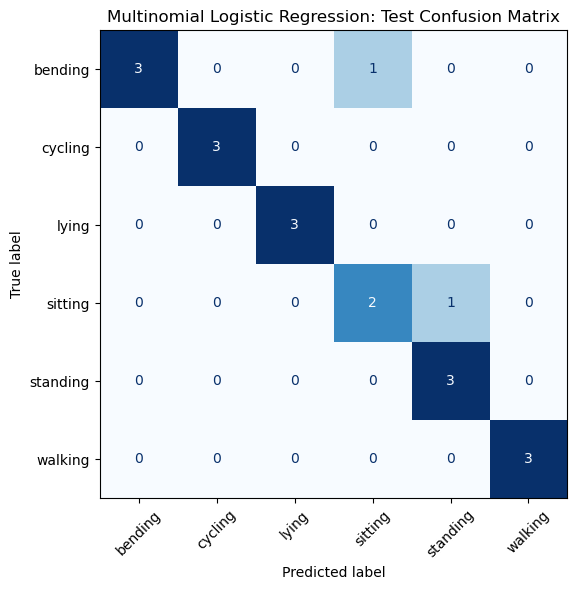

In [67]:
# Extract test features using the selected l
X_test_multi = extract_features(test_data, best_multi_l)

# The fitted pipeline automatically applies training-set scaling
multi_pred = best_multi_model.predict(X_test_multi)
multi_prob = best_multi_model.predict_proba(X_test_multi)

classes = best_multi_model.named_steps["logistic"].classes_

multi_test_accuracy = accuracy_score(y_test_multi, multi_pred)
multi_test_error = 1 - multi_test_accuracy

print(f"Test accuracy: {multi_test_accuracy:.4f}")
print(f"Test error rate: {multi_test_error:.4f}")

cm_multi = confusion_matrix(
    y_test_multi, multi_pred, labels=classes
)

fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm_multi,
    display_labels=classes
).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False
)

ax.set_title("Multinomial Logistic Regression: Test Confusion Matrix")

plt.tight_layout()
plt.show()

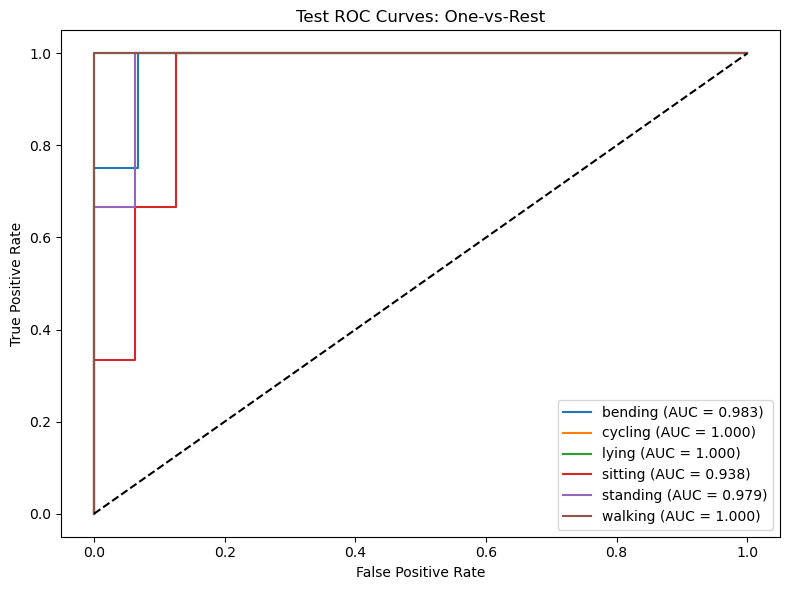

,Activity,AUC
0,bending,0.983333
1,cycling,1.000000
2,lying,1.000000
3,sitting,0.937500
4,standing,0.979167
5,walking,1.000000


Macro-average AUC: 0.9833


In [68]:
fig, ax = plt.subplots(figsize=(8, 6))
auc_rows = []

for i, activity in enumerate(classes):
    # Current activity versus all other activities
    y_binary = (y_test_multi == activity).astype(int)

    fpr, tpr, _ = roc_curve(y_binary, multi_prob[:, i])
    class_auc = roc_auc_score(y_binary, multi_prob[:, i])

    ax.plot(
        fpr, tpr,
        label=f"{activity} (AUC = {class_auc:.3f})"
    )

    auc_rows.append({
        "Activity": activity,
        "AUC": class_auc
    })

ax.plot([0, 1], [0, 1], "k--")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("Test ROC Curves: One-vs-Rest")
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

display(pd.DataFrame(auc_rows))

multi_macro_auc = roc_auc_score(
    y_test_multi,
    multi_prob,
    labels=classes,
    multi_class="ovr",
    average="macro"
)

print(f"Macro-average AUC: {multi_macro_auc:.4f}")

I combined bending1 and bending2 into one class, resulting in six activity classes. Using 5-fold stratified cross-validation, the best L1-penalized multinomial logistic regression model had l = 3 and C = 10, with a CV accuracy of 92.75%.

The test accuracy was 89.47%, giving a test error rate of 10.53%. The confusion matrix shows that 17 of 19 test samples were classified correctly. One bending sample was predicted as sitting, and one sitting sample was predicted as standing.

For multiclass ROC evaluation, each class was treated as positive and all remaining classes as negative. The AUC values were 0.9833 for bending, 1.0000 for cycling, 1.0000 for lying, 0.9375 for sitting, 0.9792 for standing, and 1.0000 for walking. The macro-average AUC was 0.9833, indicating strong overall discrimination on this small test set.

2(c)ii

In [69]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.model_selection import cross_val_score
from sklearn.base import clone

nb_models = {
    "GaussianNB": GaussianNB(),
    "MultinomialNB": MultinomialNB(alpha=1.0)
}

nb_results = []
best_nb = {}

for name, model in nb_models.items():
    best_cv = -1

    for l in range(1, 21):
        X = extract_features(train_data, l)

        score = cross_val_score(
            model,
            X,
            y_train_multi,
            cv=cv_multi,
            scoring="accuracy",
            n_jobs=-1
        ).mean()

        nb_results.append({
            "Model": name,
            "l": l,
            "CV Accuracy": score
        })

        if score > best_cv:
            best_cv = score

            best_nb[name] = {
                "l": l,
                "CV Accuracy": score,
                "model": clone(model).fit(X, y_train_multi)
            }

    print(
        f"{name}: Best l = {best_nb[name]['l']}, "
        f"CV Accuracy = {best_cv:.4f}"
    )

nb_results_df = pd.DataFrame(nb_results)
display(nb_results_df)

GaussianNB: Best l = 1, CV Accuracy = 0.8846
MultinomialNB: Best l = 8, CV Accuracy = 0.8835


,Model,l,CV Accuracy
0,GaussianNB,1,0.884615
1,GaussianNB,2,0.812088
2,GaussianNB,3,0.725275
3,GaussianNB,4,0.753846
4,GaussianNB,5,0.736264
5,GaussianNB,6,0.694505
6,GaussianNB,7,0.709890
7,GaussianNB,8,0.752747
8,GaussianNB,9,0.620879
9,GaussianNB,10,0.664835


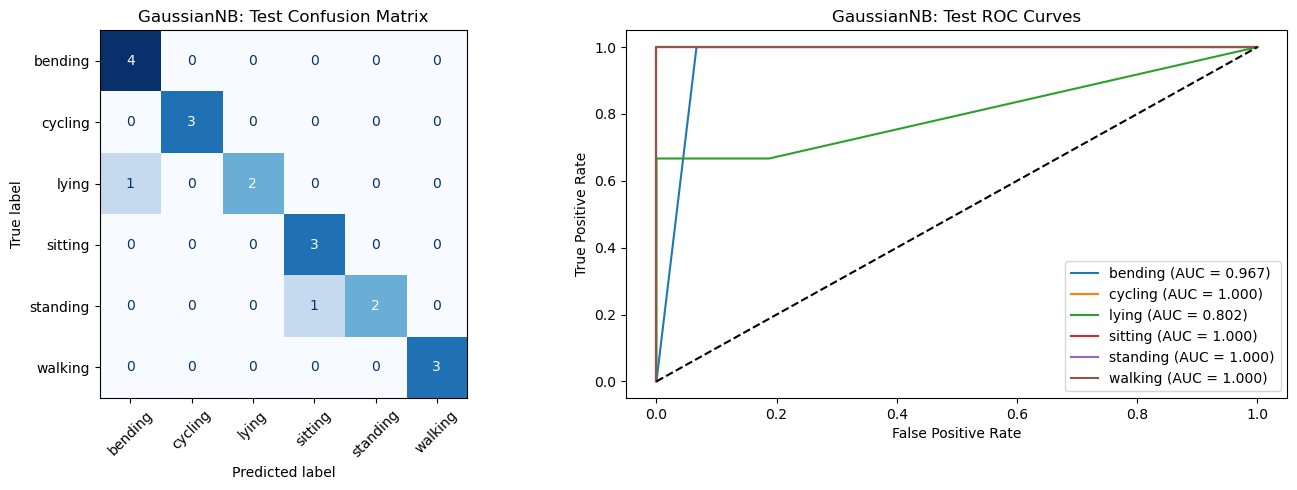

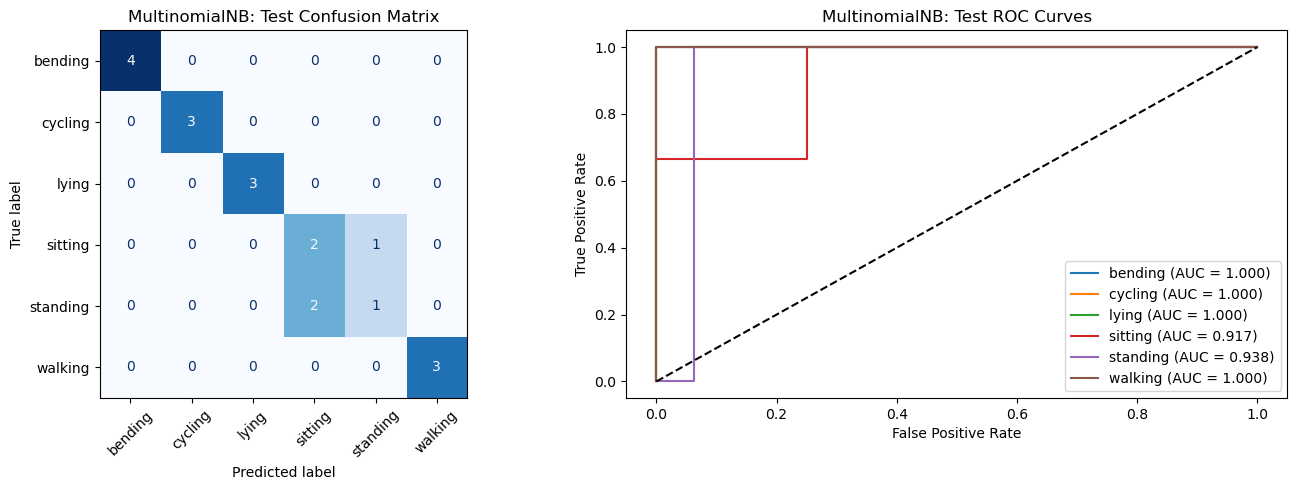

,Model,Best l,CV Accuracy,Test Accuracy,Test Error,Macro AUC
0,GaussianNB,1,0.884615,0.894737,0.105263,0.961458
1,MultinomialNB,8,0.883516,0.842105,0.157895,0.975694


,Model,Activity,AUC
0,GaussianNB,bending,0.966667
1,GaussianNB,cycling,1.000000
2,GaussianNB,lying,0.802083
3,GaussianNB,sitting,1.000000
4,GaussianNB,standing,1.000000
5,GaussianNB,walking,1.000000
6,MultinomialNB,bending,1.000000
7,MultinomialNB,cycling,1.000000
8,MultinomialNB,lying,1.000000
9,MultinomialNB,sitting,0.916667


In [70]:
nb_summary = []
nb_auc_rows = []

for name, result in best_nb.items():
    model = result["model"]
    X_test_nb = extract_features(test_data, result["l"])

    pred = model.predict(X_test_nb)
    prob = model.predict_proba(X_test_nb)
    nb_classes = model.classes_

    test_acc = accuracy_score(y_test_multi, pred)

    macro_auc = roc_auc_score(
        y_test_multi,
        prob,
        labels=nb_classes,
        multi_class="ovr",
        average="macro"
    )

    nb_summary.append({
        "Model": name,
        "Best l": result["l"],
        "CV Accuracy": result["CV Accuracy"],
        "Test Accuracy": test_acc,
        "Test Error": 1 - test_acc,
        "Macro AUC": macro_auc
    })

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Confusion matrix
    cm = confusion_matrix(
        y_test_multi, pred, labels=nb_classes
    )

    ConfusionMatrixDisplay(
        cm, display_labels=nb_classes
    ).plot(
        ax=axes[0],
        cmap="Blues",
        xticks_rotation=45,
        colorbar=False
    )

    axes[0].set_title(f"{name}: Test Confusion Matrix")

    # One-vs-rest ROC curves
    for i, activity in enumerate(nb_classes):
        y_binary = (y_test_multi == activity).astype(int)

        fpr, tpr, _ = roc_curve(y_binary, prob[:, i])
        class_auc = roc_auc_score(y_binary, prob[:, i])

        axes[1].plot(
            fpr, tpr,
            label=f"{activity} (AUC = {class_auc:.3f})"
        )

        nb_auc_rows.append({
            "Model": name,
            "Activity": activity,
            "AUC": class_auc
        })

    axes[1].plot([0, 1], [0, 1], "k--")
    axes[1].set_xlabel("False Positive Rate")
    axes[1].set_ylabel("True Positive Rate")
    axes[1].set_title(f"{name}: Test ROC Curves")
    axes[1].legend(loc="lower right")

    plt.tight_layout()
    plt.show()

nb_comparison = pd.DataFrame(nb_summary)
display(nb_comparison)
display(pd.DataFrame(nb_auc_rows))

Gaussian Naive Bayes selected l = 1, with a cross-validation accuracy of 88.46%. Its test accuracy was 89.47%, corresponding to a test error of 10.53% (2 misclassified samples out of 19). Its macro-average AUC was 0.9615.

Multinomial Naive Bayes selected l = 8, with a cross-validation accuracy of 88.35%. Its test accuracy was 84.21%, corresponding to a test error of 15.79% (3 misclassified samples out of 19). Its macro-average AUC was 0.9757.

Gaussian Naive Bayes performed better in terms of test classification accuracy, while Multinomial Naive Bayes had a higher macro-average AUC.

2(c)iii

L1-penalized multinomial logistic regression performed best overall in this experiment. It had the highest cross-validation accuracy (92.75%) and macro-average test AUC (0.9833). Its test accuracy was 89.47%, equal to Gaussian Naive Bayes and higher than Multinomial Naive Bayes (84.21%). Therefore, I would prefer L1-penalized multinomial logistic regression, although its test classification accuracy did not exceed Gaussian Naive Bayes on this small test set.

3 ISLR 4.8.3

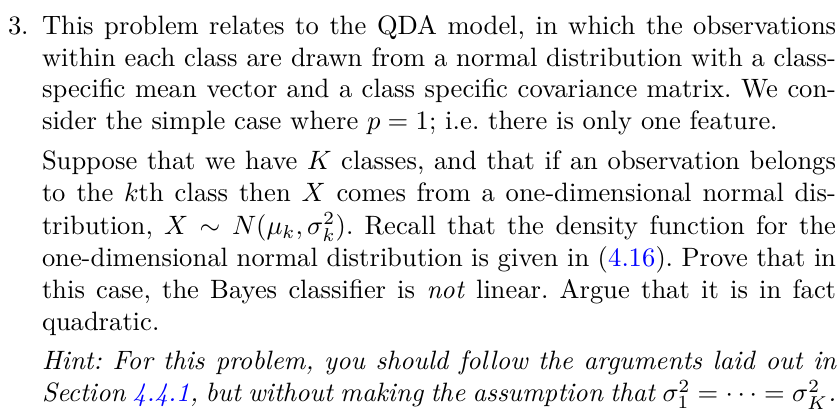

Let $\pi_k=P(Y=k)$ be the prior probability of class $k$. By Bayes' theorem,

$$
P(Y=k\mid X=x)
=
\frac{\pi_k f_k(x)}{\sum_{j=1}^{K}\pi_j f_j(x)}.
$$

Since the denominator is the same for all classes, the Bayes classifier assigns $x$ to the class that maximizes $\pi_k f_k(x)$.

The normal density for class $k$ is

$$
f_k(x)=\frac{1}{\sqrt{2\pi}\sigma_k}
\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right).
$$

Taking the logarithm and dropping the constant shared by all classes gives

$$
\delta_k(x)=\log\pi_k-\log\sigma_k
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.
$$

Expanding the squared term,

$$
\delta_k(x)=
-\frac{1}{2\sigma_k^2}x^2
+\frac{\mu_k}{\sigma_k^2}x
-\frac{\mu_k^2}{2\sigma_k^2}
-\log\sigma_k+\log\pi_k.
$$

The decision boundary between classes $k$ and $j$ satisfies $\delta_k(x)=\delta_j(x)$. The coefficient of $x^2$ in their difference is

$$
\frac{1}{2\sigma_j^2}-\frac{1}{2\sigma_k^2}.
$$

When the class variances differ, this coefficient is nonzero, so the decision equation is quadratic in $x$. Therefore, the Bayes classifier is generally quadratic rather than linear. If all class variances are equal, the quadratic terms cancel, giving the linear discriminant rule of LDA.

4 ISLR 4.8.7

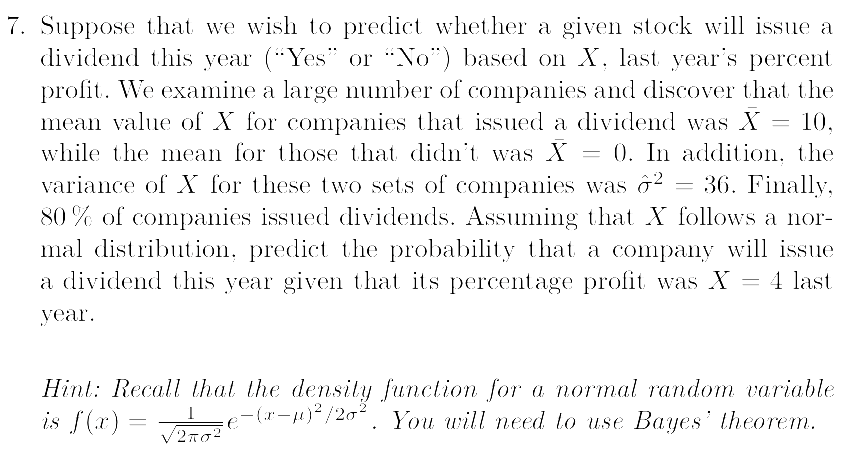

Let $Y=\text{Yes}$ indicate that a company issues a dividend. We are given

$$
P(Y=\text{Yes})=0.8,\qquad P(Y=\text{No})=0.2,
$$

$$
\mu_{\text{Yes}}=10,\qquad \mu_{\text{No}}=0,\qquad \sigma^2=36.
$$

By Bayes' theorem,

$$
P(Y=\text{Yes}\mid X=4)
=
\frac{0.8f_{\text{Yes}}(4)}
{0.8f_{\text{Yes}}(4)+0.2f_{\text{No}}(4)}.
$$

Using the normal density and cancelling the common factor $1/\sqrt{2\pi\cdot36}$,

$$
P(Y=\text{Yes}\mid X=4)
=
\frac{0.8\exp\left(-\frac{(4-10)^2}{72}\right)}
{0.8\exp\left(-\frac{(4-10)^2}{72}\right)
+0.2\exp\left(-\frac{(4-0)^2}{72}\right)}.
$$

Therefore,

$$
P(Y=\text{Yes}\mid X=4)
=
\frac{0.8e^{-1/2}}
{0.8e^{-1/2}+0.2e^{-2/9}}
\approx 0.7518.
$$

The estimated probability that the company will issue a dividend this year is approximately 75.18%.